# Student Performance Prediction - Model Development

This notebook develops and evaluates machine learning models for predicting student academic outcomes using the processed student performance dataset.

The selected predictor variables are:
- Weekly Study Hours
- Attendance Rate
- Past Exam Scores

The target variable is Pass/Fail.

Four classification algorithms are evaluated:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost

Model performance is compared using accuracy, precision, recall, and F1-score.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    brier_score_loss,
    log_loss,
    roc_auc_score
)

from sklearn.calibration import calibration_curve

from xgboost import XGBClassifier

import joblib

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Processed Dataset

In [2]:
data_path = "../data/processed/student_performance_processed.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (1792, 4)


,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Pass_Fail
0,31,68.267841,86,Pass
1,16,78.222927,73,Fail
2,21,87.525096,74,Fail
3,27,92.076483,99,Pass
4,37,98.655517,63,Pass


### 2.1 Verify Dataset

In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Pass_Fail"].value_counts())

Columns:
['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores', 'Pass_Fail']

Data types:
Study_Hours_per_Week      int64
Attendance_Rate         float64
Past_Exam_Scores          int64
Pass_Fail                   str
dtype: object

Missing values:
Study_Hours_per_Week    0
Attendance_Rate         0
Past_Exam_Scores        0
Pass_Fail               0
dtype: int64

Target distribution:
Pass_Fail
Fail    1046
Pass     746
Name: count, dtype: int64


## 3. Define Features and Target

In [4]:
X = df[
    [
        "Study_Hours_per_Week",
        "Attendance_Rate",
        "Past_Exam_Scores"
    ]
].copy()

y = df["Pass_Fail"].map({
    "Fail": 0,
    "Pass": 1
})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nEncoded target distribution:")
print(y.value_counts())

Feature matrix shape: (1792, 3)
Target shape: (1792,)

Features:
['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores']

Encoded target distribution:
Pass_Fail
0    1046
1     746
Name: count, dtype: int64


## 4. Train-Test Split

The dataset is divided into training and testing subsets. The training set is used to develop the machine learning models, while the test set is reserved for evaluating their performance on unseen data.

A stratified 80/20 split is used to preserve the Pass/Fail class distribution in both subsets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (1433, 3)
Testing features: (359, 3)

Training target distribution:
Pass_Fail
0    836
1    597
Name: count, dtype: int64

Testing target distribution:
Pass_Fail
0    210
1    149
Name: count, dtype: int64


### 4.1 Feature Scaling

Standardization is applied to the predictor variables for Logistic Regression. The scaler is fitted using only the training data to prevent information from the test set influencing model development.

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Training data shape: (1433, 3)
Testing data shape: (359, 3)


## 5. Model Development

Four classification algorithms are developed and evaluated using the same training and testing subsets to allow a consistent comparison of predictive performance.

### 5.1 Logistic Regression

In [7]:
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [8]:
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions)
logistic_recall = recall_score(y_test, logistic_predictions)
logistic_f1 = f1_score(y_test, logistic_predictions)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-score:  {logistic_f1:.4f}")

Logistic Regression Results
---------------------------
Accuracy:  0.8022
Precision: 0.7826
Recall:    0.7248
F1-score:  0.7526


In [9]:
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["Fail", "Pass"]
    )
)

              precision    recall  f1-score   support

        Fail       0.81      0.86      0.84       210
        Pass       0.78      0.72      0.75       149

    accuracy                           0.80       359
   macro avg       0.80      0.79      0.79       359
weighted avg       0.80      0.80      0.80       359



In [10]:
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions
)

print("Confusion Matrix:")
print(logistic_cm)

Confusion Matrix:
[[180  30]
 [ 41 108]]


In [11]:
# Probability estimates for the Pass class

logistic_probabilities = (
    logistic_model.predict_proba(
        X_test_scaled
    )[:, 1]
)

roc_auc = roc_auc_score(
    y_test,
    logistic_probabilities
)

print(
    "ROC-AUC:",
    round(roc_auc, 4)
)


# Probability quality metrics

brier_score = brier_score_loss(
    y_test,
    logistic_probabilities
)

logloss_score = log_loss(
    y_test,
    logistic_probabilities
)


print("\nProbability Evaluation")
print("----------------------")

print(
    "Brier Score:",
    round(brier_score, 4)
)

print(
    "Log Loss:",
    round(logloss_score, 4)
)

ROC-AUC: 0.8784

Probability Evaluation
----------------------
Brier Score: 0.136
Log Loss: 0.4331


In [12]:
fail_recall = recall_score(
    y_test,
    logistic_predictions,
    pos_label=0
)

macro_f1 = f1_score(
    y_test,
    logistic_predictions,
    average="macro"
)

print("\nAt-Risk Student Evaluation")
print("--------------------------")

print(
    "Fail-class Recall:",
    round(fail_recall, 4)
)

print(
    "Macro F1-score:",
    round(macro_f1, 4)
)


At-Risk Student Evaluation
--------------------------
Fail-class Recall: 0.8571
Macro F1-score: 0.7939


### 5.1.1 Logistic Regression Probability Calibration

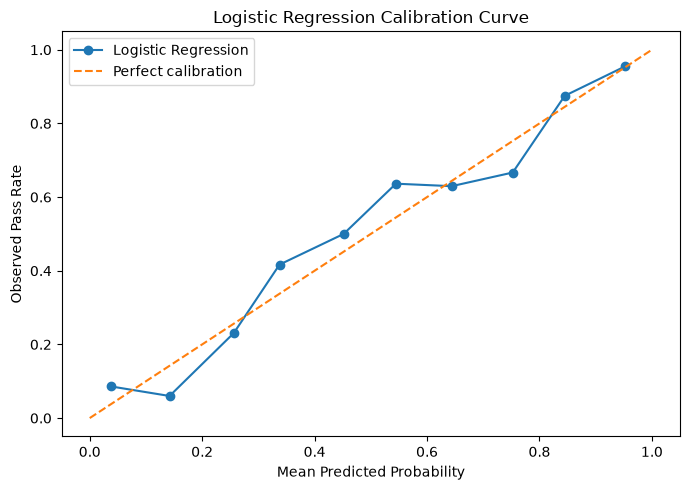

In [13]:
prob_true, prob_pred = calibration_curve(
    y_test,
    logistic_probabilities,
    n_bins=10
)

plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Pass Rate")
plt.title(
    "Logistic Regression Calibration Curve"
)

plt.legend()
plt.tight_layout()
plt.show()

### 5.2 Decision Tree

A Decision Tree classifier is trained using the original unscaled predictor variables. Decision Trees recursively split the data based on feature values to classify students as Pass or Fail.

In [14]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(X_test)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [15]:
decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_predictions
)

decision_tree_precision = precision_score(
    y_test,
    decision_tree_predictions
)

decision_tree_recall = recall_score(
    y_test,
    decision_tree_predictions
)

decision_tree_f1 = f1_score(
    y_test,
    decision_tree_predictions
)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy:  {decision_tree_accuracy:.4f}")
print(f"Precision: {decision_tree_precision:.4f}")
print(f"Recall:    {decision_tree_recall:.4f}")
print(f"F1-score:  {decision_tree_f1:.4f}")

Decision Tree Results
---------------------
Accuracy:  0.7270
Precision: 0.6835
Recall:    0.6376
F1-score:  0.6597


In [16]:
print(
    classification_report(
        y_test,
        decision_tree_predictions,
        target_names=["Fail", "Pass"]
    )
)

              precision    recall  f1-score   support

        Fail       0.75      0.79      0.77       210
        Pass       0.68      0.64      0.66       149

    accuracy                           0.73       359
   macro avg       0.72      0.71      0.72       359
weighted avg       0.73      0.73      0.73       359



In [17]:
decision_tree_cm = confusion_matrix(
    y_test,
    decision_tree_predictions
)

print("Confusion Matrix:")
print(decision_tree_cm)

Confusion Matrix:
[[166  44]
 [ 54  95]]


#### Decision Tree Overfitting Check

Training and testing accuracy are compared to assess whether the unrestricted Decision Tree may be overfitting the training data.

In [18]:
decision_tree_train_predictions = decision_tree_model.predict(X_train)

decision_tree_train_accuracy = accuracy_score(
    y_train,
    decision_tree_train_predictions
)

print(f"Training Accuracy: {decision_tree_train_accuracy:.4f}")
print(f"Testing Accuracy:  {decision_tree_accuracy:.4f}")

Training Accuracy: 1.0000
Testing Accuracy:  0.7270


### 5.3 Random Forest

A Random Forest classifier is trained using the original unscaled predictor variables. Random Forest combines multiple Decision Trees and aggregates their predictions, which can improve generalisation and reduce the overfitting associated with a single Decision Tree.

In [19]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [20]:
random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

random_forest_precision = precision_score(
    y_test,
    random_forest_predictions
)

random_forest_recall = recall_score(
    y_test,
    random_forest_predictions
)

random_forest_f1 = f1_score(
    y_test,
    random_forest_predictions
)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy:  {random_forest_accuracy:.4f}")
print(f"Precision: {random_forest_precision:.4f}")
print(f"Recall:    {random_forest_recall:.4f}")
print(f"F1-score:  {random_forest_f1:.4f}")

Random Forest Results
---------------------
Accuracy:  0.7855
Precision: 0.7466
Recall:    0.7315
F1-score:  0.7390


In [21]:
print(
    classification_report(
        y_test,
        random_forest_predictions,
        target_names=["Fail", "Pass"]
    )
)

              precision    recall  f1-score   support

        Fail       0.81      0.82      0.82       210
        Pass       0.75      0.73      0.74       149

    accuracy                           0.79       359
   macro avg       0.78      0.78      0.78       359
weighted avg       0.78      0.79      0.79       359



In [22]:
random_forest_cm = confusion_matrix(
    y_test,
    random_forest_predictions
)

print("Confusion Matrix:")
print(random_forest_cm)

Confusion Matrix:
[[173  37]
 [ 40 109]]


### 5.4 XGBoost

An XGBoost classifier is trained using the original unscaled predictor variables. XGBoost is an ensemble boosting algorithm that sequentially builds decision trees, with each new tree attempting to correct errors made by previous trees.

In [23]:
xgboost_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgboost_model.fit(X_train, y_train)

xgboost_predictions = xgboost_model.predict(X_test)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [24]:
xgboost_accuracy = accuracy_score(
    y_test,
    xgboost_predictions
)

xgboost_precision = precision_score(
    y_test,
    xgboost_predictions
)

xgboost_recall = recall_score(
    y_test,
    xgboost_predictions
)

xgboost_f1 = f1_score(
    y_test,
    xgboost_predictions
)

print("XGBoost Results")
print("----------------")
print(f"Accuracy:  {xgboost_accuracy:.4f}")
print(f"Precision: {xgboost_precision:.4f}")
print(f"Recall:    {xgboost_recall:.4f}")
print(f"F1-score:  {xgboost_f1:.4f}")

XGBoost Results
----------------
Accuracy:  0.7744
Precision: 0.7237
Recall:    0.7383
F1-score:  0.7309


In [25]:
print(
    classification_report(
        y_test,
        xgboost_predictions,
        target_names=["Fail", "Pass"]
    )
)

              precision    recall  f1-score   support

        Fail       0.81      0.80      0.81       210
        Pass       0.72      0.74      0.73       149

    accuracy                           0.77       359
   macro avg       0.77      0.77      0.77       359
weighted avg       0.78      0.77      0.77       359



In [26]:
xgboost_cm = confusion_matrix(
    y_test,
    xgboost_predictions
)

print("Confusion Matrix:")
print(xgboost_cm)

Confusion Matrix:
[[168  42]
 [ 39 110]]


#### Random Forest Overfitting Check

Training and testing accuracy are compared to examine the generalisation performance of the Random Forest model.

In [27]:
random_forest_train_predictions = random_forest_model.predict(X_train)

random_forest_train_accuracy = accuracy_score(
    y_train,
    random_forest_train_predictions
)

print(f"Training Accuracy: {random_forest_train_accuracy:.4f}")
print(f"Testing Accuracy:  {random_forest_accuracy:.4f}")

Training Accuracy: 0.9993
Testing Accuracy:  0.7855


## 6. Baseline Model Comparison

The four baseline classification models are compared using accuracy, precision, recall, and F1-score on the same unseen test set. This provides an initial assessment of their relative predictive performance before further validation and optimisation.

In [28]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logistic_accuracy,
        decision_tree_accuracy,
        random_forest_accuracy,
        xgboost_accuracy
    ],
    "Precision": [
        logistic_precision,
        decision_tree_precision,
        random_forest_precision,
        xgboost_precision
    ],
    "Recall": [
        logistic_recall,
        decision_tree_recall,
        random_forest_recall,
        xgboost_recall
    ],
    "F1-Score": [
        logistic_f1,
        decision_tree_f1,
        random_forest_f1,
        xgboost_f1
    ]
})

model_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8022,0.7826,0.7248,0.7526
1,Decision Tree,0.7270,0.6835,0.6376,0.6597
2,Random Forest,0.7855,0.7466,0.7315,0.7390
3,XGBoost,0.7744,0.7237,0.7383,0.7309


In [29]:
model_results.sort_values(
    by="F1-Score",
    ascending=False
).round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8022,0.7826,0.7248,0.7526
2,Random Forest,0.7855,0.7466,0.7315,0.7390
3,XGBoost,0.7744,0.7237,0.7383,0.7309
1,Decision Tree,0.7270,0.6835,0.6376,0.6597


### 6.1 Visual Comparison of Baseline Models

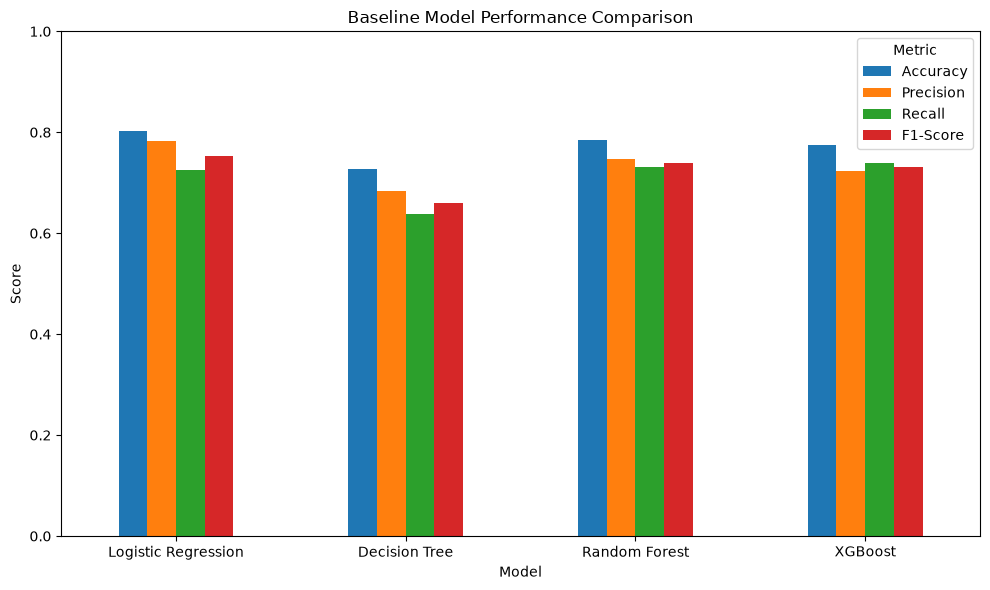

In [30]:
comparison_plot = model_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

## 7. Cross-Validation

Five-fold stratified cross-validation is used to assess the stability and generalisation performance of the four classification models. Stratification preserves the proportion of Pass and Fail outcomes within each fold.

For Logistic Regression, feature standardisation is performed within a Pipeline so that the scaler is fitted separately within each training fold, preventing data leakage during cross-validation.

### 7.1 Cross-Validation Setup

In [31]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "macro_f1": "f1_macro"
}

print("5-fold stratified cross-validation configured.")

5-fold stratified cross-validation configured.


### 7.2 Models for Cross-Validation

In [32]:
logistic_cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

decision_tree_cv_model = DecisionTreeClassifier(
    random_state=42
)

random_forest_cv_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

xgboost_cv_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

cv_models = {
    "Logistic Regression": logistic_cv_model,
    "Decision Tree": decision_tree_cv_model,
    "Random Forest": random_forest_cv_model,
    "XGBoost": xgboost_cv_model
}

print("Models prepared for cross-validation.")

Models prepared for cross-validation.


### 7.3 Cross-Validation Results

In [33]:
cv_results = {}

for model_name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[model_name] = {
    "Accuracy":
        scores["test_accuracy"].mean(),

    "Precision":
        scores["test_precision"].mean(),

    "Recall":
        scores["test_recall"].mean(),

    "F1-Score":
        scores["test_f1"].mean(),

    "Macro F1":
        scores["test_macro_f1"].mean()
}

cv_results_df = pd.DataFrame(cv_results).T

cv_results_df.round(4)

,Accuracy,Precision,Recall,F1-Score,Macro F1
Logistic Regression,0.8053,0.7684,0.7638,0.7656,0.7995
Decision Tree,0.7397,0.6932,0.6750,0.6830,0.7309
Random Forest,0.7900,0.7577,0.7303,0.7432,0.7827
XGBoost,0.7697,0.7253,0.7202,0.7222,0.7627


### 7.4 Cross-Validation Stability

In [34]:
cv_stability = {}

for model_name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_stability[model_name] = {
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean F1": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    }

cv_stability_df = pd.DataFrame(cv_stability).T

cv_stability_df.round(4)

,Mean Accuracy,Accuracy Std,Mean F1,F1 Std
Logistic Regression,0.8053,0.0109,0.7656,0.0143
Decision Tree,0.7397,0.0161,0.6830,0.0256
Random Forest,0.7900,0.0064,0.7432,0.0115
XGBoost,0.7697,0.0101,0.7222,0.0189


## 8. Hyperparameter Tuning

Controlled hyperparameter tuning is performed for the tree-based models to reduce overfitting and determine whether improved configurations provide better generalisation than the baseline models. A limited parameter grid is used to avoid unnecessary model complexity.

### 8.1 Decision Tree Tuning

In [35]:
decision_tree_params = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

decision_tree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=decision_tree_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

decision_tree_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(decision_tree_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(round(decision_tree_grid.best_score_, 4))

Best Decision Tree Parameters:
{'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 5}

Best Cross-Validation F1:
0.7291


In [36]:
best_decision_tree = decision_tree_grid.best_estimator_

best_dt_predictions = best_decision_tree.predict(X_test)

print("Tuned Decision Tree Test Results")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, best_dt_predictions):.4f}")
print(f"Precision: {precision_score(y_test, best_dt_predictions):.4f}")
print(f"Recall:    {recall_score(y_test, best_dt_predictions):.4f}")
print(f"F1-score:  {f1_score(y_test, best_dt_predictions):.4f}")

Tuned Decision Tree Test Results
--------------------------------
Accuracy:  0.7632
Precision: 0.7133
Recall:    0.7181
F1-score:  0.7157


In [37]:
best_dt_train_predictions = best_decision_tree.predict(X_train)

print(
    "Training Accuracy:",
    round(accuracy_score(y_train, best_dt_train_predictions), 4)
)

print(
    "Testing Accuracy:",
    round(accuracy_score(y_test, best_dt_predictions), 4)
)

Training Accuracy: 0.8681
Testing Accuracy: 0.7632


### 8.2 Random Forest Tuning

In [38]:
random_forest_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4]
}

random_forest_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=random_forest_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

random_forest_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(random_forest_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(round(random_forest_grid.best_score_, 4))

Best Random Forest Parameters:
{'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation F1:
0.7644


In [39]:
best_random_forest = random_forest_grid.best_estimator_

best_rf_predictions = best_random_forest.predict(X_test)

print("Tuned Random Forest Test Results")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, best_rf_predictions):.4f}")
print(f"Precision: {precision_score(y_test, best_rf_predictions):.4f}")
print(f"Recall:    {recall_score(y_test, best_rf_predictions):.4f}")
print(f"F1-score:  {f1_score(y_test, best_rf_predictions):.4f}")

Tuned Random Forest Test Results
--------------------------------
Accuracy:  0.7799
Precision: 0.7431
Recall:    0.7181
F1-score:  0.7304


In [40]:
best_rf_train_predictions = best_random_forest.predict(X_train)

print(
    "Training Accuracy:",
    round(accuracy_score(y_train, best_rf_train_predictions), 4)
)

print(
    "Testing Accuracy:",
    round(accuracy_score(y_test, best_rf_predictions), 4)
)

Training Accuracy: 0.8388
Testing Accuracy: 0.7799


## 9. Final Model Selection

The four classification models were compared primarily using five-fold stratified cross-validation on the training data, together with overfitting analysis and hyperparameter tuning for the tree-based models. Cross-validation was used as the main basis for model selection because it provides an assessment of model generalisation across multiple training-validation splits without relying on the held-out test set.

Logistic Regression was selected as the final prediction model because it achieved the strongest overall cross-validation performance among the evaluated models. It achieved a mean cross-validation Accuracy of 80.53%, Precision of 76.84%, Recall of 76.38%, F1-score of 76.56%, and Macro F1-score of 79.95%. It also provides advantages in interpretability and simplicity, which are appropriate for the proof-of-concept academic support system.

After model selection, performance on the held-out test set was examined as a final estimate of predictive performance. Logistic Regression achieved a test accuracy of 80.22%.

### 9.1 Logistic Regression Coefficient Analysis

The coefficients of the final Logistic Regression model are examined to understand the direction and relative strength of the relationship between each predictor and the probability of a student receiving a Pass outcome.

Because the predictor variables were standardised before training, their coefficients can be compared to provide an indication of their relative influence within the model.

In [41]:
feature_names = [
    "Study_Hours_per_Week",
    "Attendance_Rate",
    "Past_Exam_Scores"
]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_model.coef_[0]
})

coefficient_df["Absolute_Coefficient"] = coefficient_df["Coefficient"].abs()

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

coefficient_df

,Feature,Coefficient,Absolute_Coefficient
2,Past_Exam_Scores,1.554227,1.554227
1,Attendance_Rate,1.346980,1.346980
0,Study_Hours_per_Week,1.037042,1.037042


### 9.2 Relative Model Factor Importance

For presentation within the application, the absolute standardised Logistic Regression coefficients are converted into relative percentages. These percentages provide an interpretable indication of the relative contribution of each predictor within the fitted model.

These values should be interpreted as model-based relative importance rather than causal effects.

In [42]:
coefficient_df["Relative_Importance"] = (
    coefficient_df["Absolute_Coefficient"]
    / coefficient_df["Absolute_Coefficient"].sum()
    * 100
)

coefficient_df["Relative_Importance"] = (
    coefficient_df["Relative_Importance"].round(2)
)

coefficient_df

,Feature,Coefficient,Absolute_Coefficient,Relative_Importance
2,Past_Exam_Scores,1.554227,1.554227,39.46
1,Attendance_Rate,1.346980,1.346980,34.20
0,Study_Hours_per_Week,1.037042,1.037042,26.33


### 9.3 Probability Evaluation

In [43]:
probability_evaluation = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "Brier Score",
        "Log Loss",
        "Fail-class Recall",
        "Macro F1"
    ],
    "Value": [
        roc_auc,
        brier_score,
        logloss_score,
        fail_recall,
        macro_f1
    ]
})

probability_evaluation.round(4)

,Metric,Value
0,ROC-AUC,0.8784
1,Brier Score,0.1360
2,Log Loss,0.4331
3,Fail-class Recall,0.8571
4,Macro F1,0.7939


Because the final application presents a predicted Pass Probability, the Logistic Regression model was also evaluated using probability-based measures. The model achieved a Brier Score of 0.1360 and a Log Loss of 0.4331. The calibration curve showed that predicted probabilities generally followed the observed Pass rates, although some deviation was present across individual probability ranges.

The model also achieved a Fail-class Recall of 85.71%, indicating that approximately 85.7% of actual Fail cases in the test set were correctly identified. This is particularly relevant to the academic support system because identifying students who may require additional support is an important objective. The test-set Macro F1-score of 79.39% also indicates reasonably balanced classification performance across the Pass and Fail classes.

## 10. Save Final Prediction Model

In [44]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(logistic_model, models_dir / "logistic_regression_model.pkl")
joblib.dump(scaler, models_dir / "standard_scaler.pkl")

print("Final Logistic Regression model saved successfully.")
print("StandardScaler saved successfully.")

Final Logistic Regression model saved successfully.
StandardScaler saved successfully.


### 10.1 Save Model Factor Information

The relative importance values derived from the standardised Logistic Regression coefficients are saved for use in the application's Prediction Results page.

In [45]:
coefficient_df.to_csv(
    models_dir / "model_factor_importance.csv",
    index=False
)

print("Model factor information saved successfully.")

Model factor information saved successfully.


## 11. End-to-End Prediction Test

The saved prediction model and StandardScaler are reloaded and tested using a sample student profile. This verifies that the saved model files can process new student inputs and return both a predicted academic outcome and the associated probability for use within the Streamlit application.

In [46]:
loaded_model = joblib.load("../models/logistic_regression_model.pkl")
loaded_scaler = joblib.load("../models/standard_scaler.pkl")

print("Saved model and scaler loaded successfully.")

Saved model and scaler loaded successfully.


### 11.1 Sample Student Input

In [47]:
sample_student = pd.DataFrame({
    "Study_Hours_per_Week": [25],
    "Attendance_Rate": [85],
    "Past_Exam_Scores": [80]
})

sample_student

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores
0,25,85,80


In [48]:
sample_student_scaled = loaded_scaler.transform(sample_student)

prediction = loaded_model.predict(sample_student_scaled)[0]

prediction_probability = loaded_model.predict_proba(
    sample_student_scaled
)[0]

predicted_label = "Pass" if prediction == 1 else "Fail"

pass_probability = prediction_probability[1] * 100
fail_probability = prediction_probability[0] * 100

print("Predicted Outcome:", predicted_label)
print(f"Pass Probability: {pass_probability:.2f}%")
print(f"Fail Probability: {fail_probability:.2f}%")

Predicted Outcome: Pass
Pass Probability: 55.72%
Fail Probability: 44.28%


In [49]:
sample_student_2 = pd.DataFrame({
    "Study_Hours_per_Week": [12],
    "Attendance_Rate": [55],
    "Past_Exam_Scores": [55]
})

sample_student_2_scaled = loaded_scaler.transform(sample_student_2)

prediction_2 = loaded_model.predict(sample_student_2_scaled)[0]

probabilities_2 = loaded_model.predict_proba(
    sample_student_2_scaled
)[0]

predicted_label_2 = "Pass" if prediction_2 == 1 else "Fail"

print("Predicted Outcome:", predicted_label_2)
print(f"Pass Probability: {probabilities_2[1] * 100:.2f}%")
print(f"Fail Probability: {probabilities_2[0] * 100:.2f}%")

Predicted Outcome: Fail
Pass Probability: 0.10%
Fail Probability: 99.90%


# Final Model Verification

In [50]:
feature_names = [
    "Study_Hours_per_Week",
    "Attendance_Rate",
    "Past_Exam_Scores"
]

print("Scaler values:\n")

for feature, mean, scale in zip(
    feature_names,
    scaler.mean_,
    scaler.scale_
):
    print(
        f"{feature}: mean={mean:.4f}, std={scale:.4f}"
    )

Scaler values:

Study_Hours_per_Week: mean=25.9742, std=8.7962
Attendance_Rate: mean=77.4877, std=13.8084
Past_Exam_Scores: mean=77.1026, std=14.5301


In [51]:
print("Intercept:")
print(logistic_model.intercept_[0])

print("\nCoefficients:")

for feature, coefficient in zip(
    feature_names,
    logistic_model.coef_[0]
):
    print(f"{feature}: {coefficient:.6f}")

Intercept:
-0.698089536594401

Coefficients:
Study_Hours_per_Week: 1.037042
Attendance_Rate: 1.346980
Past_Exam_Scores: 1.554227


In [52]:
import pandas as pd

student = pd.DataFrame({
    "Study_Hours_per_Week": [30],
    "Attendance_Rate": [80],
    "Past_Exam_Scores": [75]
})

student

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores
0,30,80,75


In [53]:
student_scaled = scaler.transform(student)

print("Scaled values:")
print(student_scaled)

Scaled values:
[[ 0.45767647  0.18193818 -0.14470491]]


In [54]:
scaled_values = student_scaled[0]
coefficients = logistic_model.coef_[0]
intercept = logistic_model.intercept_[0]

contributions = scaled_values * coefficients

for feature, raw, scaled, coef, contribution in zip(
    feature_names,
    student.iloc[0],
    scaled_values,
    coefficients,
    contributions
):
    print(f"\n{feature}")
    print(f"Raw value: {raw}")
    print(f"Scaled value: {scaled:.4f}")
    print(f"Coefficient: {coef:.4f}")
    print(f"Contribution: {contribution:.4f}")

print(f"\nIntercept: {intercept:.4f}")


Study_Hours_per_Week
Raw value: 30
Scaled value: 0.4577
Coefficient: 1.0370
Contribution: 0.4746

Attendance_Rate
Raw value: 80
Scaled value: 0.1819
Coefficient: 1.3470
Contribution: 0.2451

Past_Exam_Scores
Raw value: 75
Scaled value: -0.1447
Coefficient: 1.5542
Contribution: -0.2249

Intercept: -0.6981


In [55]:
import numpy as np

logit = intercept + contributions.sum()

manual_probability = (
    1 / (1 + np.exp(-logit))
)

model_probability = (
    logistic_model.predict_proba(student_scaled)[0, 1]
)

prediction = logistic_model.predict(student_scaled)[0]

print(f"Logit: {logit:.6f}")
print(
    f"Manual Pass Probability: "
    f"{manual_probability * 100:.2f}%"
)
print(
    f"Model Pass Probability: "
    f"{model_probability * 100:.2f}%"
)
print(
    "Predicted Outcome:",
    "Pass" if prediction == 1 else "Fail"
)

Logit: -0.203297
Manual Pass Probability: 44.94%
Model Pass Probability: 44.94%
Predicted Outcome: Fail


FINAL MODEL VERIFICATION SUMMARY
--------------------------------------------------

The test student studied 30 hours per week, had 80% attendance,
and had a past exam score of 75.

The model estimated a Pass Probability of 44.94%.

The manual calculation also produced 44.94%.

Because both probabilities match, this confirms that the saved
scaler and Logistic Regression model are being applied correctly.

Study Hours and Attendance were above the averages in the training
data, so they increased the prediction towards Pass.

The Past Exam Score of 75 was slightly below the training average
of 77.10, so it slightly reduced the Pass prediction.

The final probability was 44.94%, which is below the 50%
classification threshold. The model therefore predicted Fail.

The probability is close to 50%, so this should be interpreted as
a borderline prediction rather than a strong prediction of failure.

Conclusion: The prediction calculation is working as expected and
no technical error was identified in this verification.